
1. Ý tưởng cốt lõi:
Đây là chiến lược Trend Following Breakout (Theo xu hướng phá vỡ). Nó xác định xu hướng bằng đường MA, sau đó đặt lệnh chờ (Stop Order) tại mức giá biến động mạnh (kết hợp Keltner Channel và Bollinger Bands).
2. Chỉ báo kỹ thuật (Indicators):

SMA (50): Đường trung bình động đơn giản chu kỳ 50. Dùng để lọc xu hướng.

Keltner Channel (KC): Chu kỳ 20, Hệ số 1.9.

Bollinger Bands (BB): Chu kỳ 20, Hệ số 1.9 (Dùng để tính độ rộng dải băng - Volatility).

ATR: Dùng nhiều chu kỳ khác nhau cho SL (20), PT (25) và Trailing (185).

3. Logic Giao dịch:
Tín hiệu Xu hướng (Signal):

Xu hướng Tăng: Giá đóng cửa (Close) > SMA(50).

Xu hướng Giảm: Giá đóng cửa (Close) < SMA(50).

Điểm vào lệnh (Entry - Pending Stop):

Công thức: Dùng biên trên/dưới của Keltner cộng thêm một phần biến động của Bollinger Bands.

Buy Stop: KC_Upper + (0.6 * BB_Range).

Sell Stop: KC_Lower - (0.6 * BB_Range).

Giải thích: BB_Range là chiều rộng của dải Bollinger (Upper - Lower). Chiến lược này yêu cầu giá phải phá vỡ rất mạnh (vượt qua cả Keltner và một phần Bollinger) mới vào lệnh.

Hủy lệnh (Expiration): Sau 3 cây nến (3 giờ).

Thoát lệnh (Exit):

Stop Loss: 2.3 * ATR(20).

Profit Target: 3.2 * ATR(25).

Trailing Stop: 2.3 * ATR(185) (Dùng ATR chu kỳ rất dài 185 để Trailing mượt).

Time Exit: Thoát sau 16 cây nến.

📡 Checking connection to Binance...
⏳ Downloading BTCUSDT (1h)...
   -> Downloaded: 5000 candles
   -> Downloaded: 10000 candles
   -> Downloaded: 15000 candles
   -> Downloaded: 20000 candles
   -> Downloaded: 25000 candles
   -> Downloaded: 30000 candles
   -> Downloaded: 35000 candles
   -> Downloaded: 40000 candles
   -> Downloaded: 45000 candles
   -> Downloaded: 50000 candles
   -> Downloaded: 55000 candles
   -> Downloaded: 60000 candles
   -> Downloaded: 65000 candles
   -> Downloaded: 70000 candles
⚙️ Calculating indicators & Running Strategy_4_24_153...

📊 BACKTEST: Strategy_4_24_153 (BTCUSDT)
  Final Equity: 42,609.72
  Total Return: 326.10%
 CAGR (approx): 18.94%
  Max Drawdown: -38.31%
  Sharpe Ratio: 0.74
        Trades: 1264
       Winrate: 46.68%
 Profit Factor: 1.19


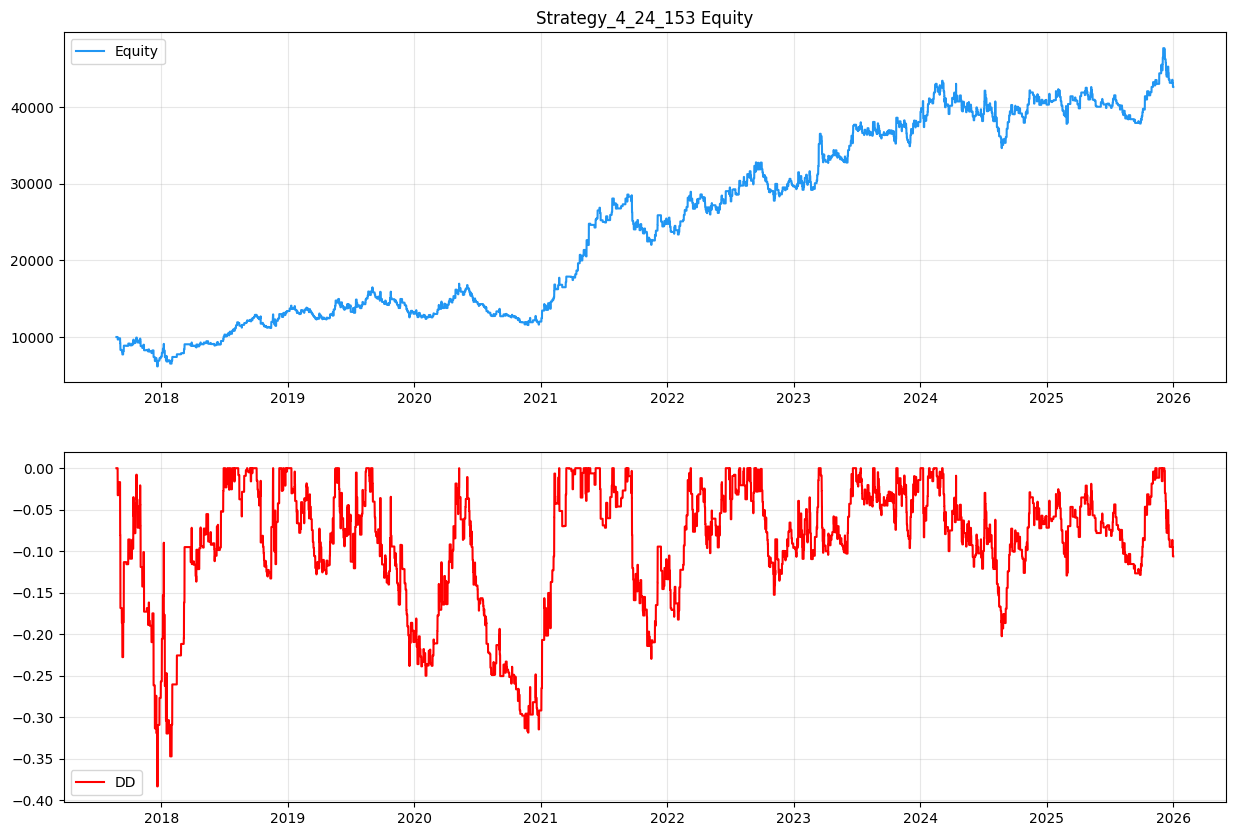

In [5]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNG CHIẾN LƯỢC
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',
    'START_DATE': '01/01/2015',
    'END_DATE': '31/12/2025',
    'INITIAL_CAPITAL': 10000.0,

    # --- Indicators Parameters ---
    'MA_PERIOD': 50,         # SMA 50 xác định xu hướng
    'KC_BB_PERIOD': 20,      # Chu kỳ cho KC và BB
    'KC_MULT': 1.9,          # Hệ số Keltner
    'BB_MULT': 1.9,          # Hệ số Bollinger

    'ATR_SL_PERIOD': 20,     # ATR tính SL
    'ATR_PT_PERIOD': 25,     # ATR tính PT
    'ATR_TRAIL_PERIOD': 185, # ATR tính Trailing (Theo Java code)

    # --- Entry & Management ---
    'ENTRY_MULT': 0.6,       # Hệ số nhân với BB Range
    'SL_COEF': 2.3,          # 2.3 * ATR(20)
    'PT_COEF': 3.2,          # 3.2 * ATR(25)
    'TRAIL_COEF': 2.3,       # 2.3 * ATR(185)

    'ORDER_EXPIRATION': 3,   # Hủy lệnh sau 3 nến (Theo Java: sqSetOrderExpiration(ticket, 3))
    'TIME_EXIT_BARS': 16,    # Thoát sau 16 nến (Theo Java: ExitAfterBars = 16)

    # Costs
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0002
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU (Giữ nguyên Template chuẩn)
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    print(f"📡 Checking connection to Binance...")
    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451:
            print("⚠️ US IP detected. Switching to Binance.US...")
            base_url = "https://api.binance.us"
            if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
    except:
        print("⚠️ Connection failed. Retrying with Binance.US...")
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    url = base_url + "/api/v3/klines"
    start_time = str_to_millis(start_str)

    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {req_symbol} ({interval})...")

    while start_time < end_time:
        params = {"symbol": req_symbol, "interval": interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200: break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            if len(all_klines) % 5000 == 0:
                print(f"   -> Downloaded: {len(all_klines)} candles")
            time.sleep(0.05)
        except: break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# ==============================================================================
# BƯỚC 4: BACKTEST ENGINE (Logic: Strategy_4_24_153)
# ==============================================================================
def run_strategy(df):
    print("⚙️ Calculating indicators & Running Strategy_4_24_153...")
    df = df.copy()
    c = CONFIG

    # --- A. INDICATORS ---
    # 1. Trend Filter: SMA 50
    df['SMA_Trend'] = ta.sma(df['Close'], length=c['MA_PERIOD'])

    # 2. Keltner Channels (20, 1.9)
    # Lưu ý: StrategyQuant thường dùng SMA cho KC Basis
    kc_basis = ta.sma(df['Close'], length=c['KC_BB_PERIOD'])
    kc_atr = ta.atr(df['High'], df['Low'], df['Close'], length=c['KC_BB_PERIOD'])
    df['KC_Upper'] = kc_basis + (c['KC_MULT'] * kc_atr)
    df['KC_Lower'] = kc_basis - (c['KC_MULT'] * kc_atr)

    # 3. Bollinger Bands (20, 1.9) -> Tính BB Range
    bb = ta.bbands(df['Close'], length=c['KC_BB_PERIOD'], std=c['BB_MULT'])
    # Pandas_ta trả về cột: BBL, BBM, BBU, BBB, BBP. Ta lấy BBU và BBL
    # BB Range = Upper - Lower

    # FIX: Dynamically find Bollinger Band column names to avoid KeyError due to float formatting
    bb_upper_col = None
    bb_lower_col = None
    for col in bb.columns:
        if col.startswith('BBU_'):
            bb_upper_col = col
        if col.startswith('BBL_'):
            bb_lower_col = col

    if bb_upper_col and bb_lower_col:
        df['BB_Range'] = bb[bb_upper_col] - bb[bb_lower_col]
    else:
        print("Warning: Could not find Bollinger Bands Upper/Lower columns. Check pandas_ta version or input data.")
        df['BB_Range'] = np.nan # Assign NaN to prevent further errors

    # 4. ATRs cho quản lý vốn
    df['ATR_SL'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_SL_PERIOD'])
    df['ATR_PT'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_PT_PERIOD'])
    df['ATR_Trail'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_TRAIL_PERIOD'])

    df.dropna(inplace=True)

    # --- B. INITIALIZATION ---
    capital = c['INITIAL_CAPITAL']
    position = 0; entry_price = 0.0; entry_idx = 0
    sl_price = 0.0; tp_price = 0.0
    pending_orders = []; trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Numpy Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index

    # Indicators Array
    sma_trend = df['SMA_Trend'].values
    kc_upper = df['KC_Upper'].values; kc_lower = df['KC_Lower'].values
    bb_range = df['BB_Range'].values
    atr_sl = df['ATR_SL'].values; atr_pt = df['ATR_PT'].values; atr_trail = df['ATR_Trail'].values

    # --- C. MAIN LOOP ---
    for i in range(1, len(df)):

        # 1. QUẢN LÝ LỆNH ĐANG CHẠY (EXIT)
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]

            if position == 1:
                if lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif highs[i] >= tp_price:
                    exit_signal = True; exit_reason = "PT Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            elif position == -1:
                if highs[i] >= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif lows[i] <= tp_price:
                    exit_signal = True; exit_reason = "PT Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            if exit_signal:
                # Tính PnL
                if position == 1:
                    real_exit = min(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 - c['SLIPPAGE'])
                    pnl = (real_exit - entry_price) / entry_price
                else:
                    real_exit = max(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 + c['SLIPPAGE'])
                    pnl = (entry_price - real_exit) / entry_price

                net_pnl = pnl - (c['FEE_RATE'] * 2)
                capital += (capital * net_pnl)

                trades.append({'Date': times[i], 'Type': 'Long' if position == 1 else 'Short', 'Reason': exit_reason, 'PnL': capital * net_pnl, 'Equity': capital})
                position = 0; pending_orders = []

            else:
                # Trailing Stop (ATR 185)
                # Logic: TrailingStopCoef * sqATR(Current,0,185,1)
                trail_dist = c['TRAIL_COEF'] * atr_trail[i]

                if position == 1:
                    new_sl = closes[i] - trail_dist
                    if new_sl > sl_price: sl_price = new_sl
                elif position == -1:
                    new_sl = closes[i] + trail_dist
                    if new_sl < sl_price: sl_price = new_sl

        # 2. XỬ LÝ LỆNH CHỜ (ENTRY)
        if position == 0:
            # Lọc lệnh hết hạn (3 nến)
            pending_orders = [o for o in pending_orders if (i - o['created_idx']) < c['ORDER_EXPIRATION']]

            triggered = None
            for order in pending_orders:
                if order['type'] == 'buy' and highs[i] >= order['price']:
                    triggered = order; exec_price = max(opens[i], order['price']) if opens[i] > order['price'] else order['price']
                    break
                elif order['type'] == 'sell' and lows[i] <= order['price']:
                    triggered = order; exec_price = min(opens[i], order['price']) if opens[i] < order['price'] else order['price']
                    break

            if triggered:
                entry_idx = i
                if triggered['type'] == 'buy':
                    position = 1
                    entry_price = exec_price * (1 + c['SLIPPAGE'])
                    sl_price = exec_price - (c['SL_COEF'] * atr_sl[i])
                    tp_price = exec_price + (c['PT_COEF'] * atr_pt[i])
                else:
                    position = -1
                    entry_price = exec_price * (1 - c['SLIPPAGE'])
                    sl_price = exec_price + (c['SL_COEF'] * atr_sl[i])
                    tp_price = exec_price - (c['PT_COEF'] * atr_pt[i])

                pending_orders = []

        # 3. TẠO TÍN HIỆU MỚI (Logic Strategy 11111)
        if position == 0:
            # Signal: Close > SMA(50) -> Long Trend
            is_uptrend = closes[i] > sma_trend[i]
            is_downtrend = closes[i] < sma_trend[i]

            # Entry Calculation: KC +/- (0.6 * BB Range)
            # BB_Range = Upper - Lower
            entry_offset = c['ENTRY_MULT'] * bb_range[i]

            if is_uptrend:
                buy_price = kc_upper[i] + entry_offset
                pending_orders.append({'type': 'buy', 'price': buy_price, 'created_idx': i})

            if is_downtrend:
                sell_price = kc_lower[i] - entry_offset
                pending_orders.append({'type': 'sell', 'price': sell_price, 'created_idx': i})

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: RUN & REPORT
# ==============================================================================
if __name__ == "__main__":
    df = fetch_binance_kline_df(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])

    if not df.empty:
        equity, trades_df = run_strategy(df)

        if not trades_df.empty:
            final_equity = equity.iloc[-1]
            total_return = (final_equity - CONFIG['INITIAL_CAPITAL']) / CONFIG['INITIAL_CAPITAL']

            rolling_max = equity.cummax()
            dd = (equity - rolling_max) / rolling_max
            max_dd = dd.min()

            wins = trades_df[trades_df['PnL'] > 0]
            losses = trades_df[trades_df['PnL'] <= 0]
            winrate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0

            gross_profit = wins['PnL'].sum(); gross_loss = abs(losses['PnL'].sum())
            profit_factor = gross_profit / gross_loss if gross_loss != 0 else 0

            days = (equity.index[-1] - equity.index[0]).days
            cagr = ((final_equity / CONFIG['INITIAL_CAPITAL']) ** (365.0 / days)) - 1 if days > 0 else 0

            returns = equity.pct_change().dropna()
            sharpe_ratio = (returns.mean() / returns.std()) * np.sqrt(365 * 24) if returns.std() != 0 else 0

            print(f"\n{'='*30}")
            print(f"📊 BACKTEST: Strategy_4_24_153 ({CONFIG['SYMBOL']})")
            print(f"{'='*30}")
            print(f"{'Final Equity:':>15} {final_equity:,.2f}")
            print(f"{'Total Return:':>15} {total_return:.2%}")
            print(f"{'CAGR (approx):':>15} {cagr:.2%}")
            print(f"{'Max Drawdown:':>15} {max_dd:.2%}")
            print(f"{'Sharpe Ratio:':>15} {sharpe_ratio:.2f}")
            print(f"{'Trades:':>15} {len(trades_df)}")
            print(f"{'Winrate:':>15} {winrate:.2%}")
            print(f"{'Profit Factor:':>15} {profit_factor:.2f}")
            print(f"{'='*30}")

            plt.figure(figsize=(15, 10))
            plt.subplot(2, 1, 1)
            plt.plot(equity, label='Equity', color='#2196F3'); plt.grid(True, alpha=0.3); plt.legend()
            plt.title('Strategy_4_24_153 Equity')
            plt.subplot(2, 1, 2)
            plt.plot(dd, label='DD', color='red'); plt.grid(True, alpha=0.3); plt.legend()
            plt.show()
        else:
            print("⚠️ No trades executed.")
    else:
        print("❌ No data.")

In [3]:
df

,Open,High,Low,Close,Volume
timestamp,,,,,
2020-01-01 00:00:00,7195.24,7196.25,7175.46,7177.02,511.814901
2020-01-01 01:00:00,7176.47,7230.00,7175.71,7216.27,883.052603
2020-01-01 02:00:00,7215.52,7244.87,7211.41,7242.85,655.156809
2020-01-01 03:00:00,7242.66,7245.00,7220.00,7225.01,783.724867
2020-01-01 04:00:00,7225.00,7230.00,7215.03,7217.27,467.812578
...,...,...,...,...,...
2025-12-31 19:00:00,87684.08,87870.02,87516.70,87541.85,622.188590
2025-12-31 20:00:00,87541.85,87712.13,87250.00,87662.01,770.327430
2025-12-31 21:00:00,87662.01,87879.04,87662.01,87799.97,383.855500
